# Taş · Kağıt · Makas — Model Eğitimi

Bu notebook iki modeli **aynı data, aynı augmentation ve aynı train / val / test bölünmesiyle** eğitir:

- **Model A:** sıfırdan eğitilen kendi CNN'in (25.6M parametre)
- **Model B:** ImageNet'te önceden eğitilmiş (pretrained) ConvNeXt-Tiny (27.8M parametre), senin datanla fine-tune edilir

**Nasıl kullanılır?**
1. Sağ üstten kernel olarak projenin `.venv` ortamını seç.
2. **Bölüm 0 – Ortak hazırlık** hücrelerini sırayla çalıştır (her seferinde gerekir).
3. Sonra **sadece sıradaki modelin bölümünü** çalıştır. Önce Model A. Model B'nin bölümünü, Model A'yı kamerada denedikten sonra çalıştıracağız.
4. İki model de eğitilince **Bölüm 3 – Karşılaştırma**'yı çalıştır.

> Altın kural: **test datası eğitimde hiç kullanılmaz.** Sadece en sonda, modelin hiç görmediği fotoğraflarda ne kadar iyi olduğunu ölçmek için bir kez kullanılır.

---
## Bölüm 0 — Ortak hazırlık

### 0.1 Kütüphaneler ve ayarlar
Kütüphaneleri yükler, sunucunun 48 çekirdeğinin hepsini PyTorch'a verir ve rastgeleliği sabitler (aynı kod tekrar çalışınca aynı sonucu versin diye).

**Çıktıda bak:** PyTorch sürümü ve `48 thread` yazmalı.

In [1]:
import json, logging, os, random, time, warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

from live import CNNLive, FineTuneLive  # canlı eğitim panelleri (değiştirilmeden kopyalandı)

ROOT = Path.cwd()
SPLIT = ROOT / "data" / "split"
MODELS = ROOT / "models"
MODELS.mkdir(exist_ok=True)

torch.set_num_threads(48)
warnings.filterwarnings("ignore", category=UserWarning)
logging.getLogger().setLevel(logging.ERROR)  # onnxruntime quantization uyarıları
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

IMG_SIZE = 224
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]  # ImageNet normalizasyonu (iki model için aynı)
TR = {"rock": "Taş", "paper": "Kağıt", "scissors": "Makas"}

print("PyTorch", torch.__version__, "|", torch.get_num_threads(), "thread")

PyTorch 2.14.1+cpu | 48 thread


### 0.2 Data augmentation ve datasetler
**Augmentation**, eğitim sırasında her fotoğrafı biraz değiştirerek modeli farklı koşullara hazırlar: hafif kırpma/yakınlaştırma, ayna çevirme (sağ ↔ sol el), ±20° döndürme, parlaklık / kontrast / renk değişimi. Böylece model 298 fotoğrafı ezberlemek yerine hareketin şeklini öğrenmeye zorlanır.

Validation ve test fotoğrafları **değiştirilmez**: modeli gerçek haliyle ölçeriz.

**Çıktıda bak:** üç split'te üç sınıfın sayıları. Sayılar Aşama 2'deki tabloyla aynı olmalı (train 298, val 67, test 70).

In [2]:
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0), ratio=(0.85, 1.18)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.35, contrast=0.35, saturation=0.25, hue=0.03),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

train_ds = datasets.ImageFolder(SPLIT / "train", train_tf)
val_ds = datasets.ImageFolder(SPLIT / "val", eval_tf)
test_ds = datasets.ImageFolder(SPLIT / "test", eval_tf)
CLASSES = train_ds.classes  # klasör adları, alfabetik: paper, rock, scissors
assert val_ds.classes == CLASSES == test_ds.classes

# num_workers=0: bu sunucunun paylaşımlı belleği (/dev/shm) sadece 64 MB, işçi süreçleri batch'leri oraya
# sığdıramıyor. Data küçük olduğu için ana süreçte yüklemek epoch başına ~1.6 sn sürüyor; hesaplamayı zaten
# torch.set_num_threads(48) ile 48 çekirdeğin hepsi yapıyor.
loader = lambda ds, shuffle: DataLoader(ds, batch_size=32, shuffle=shuffle, num_workers=0)
train_dl, val_dl, test_dl = loader(train_ds, True), loader(val_ds, False), loader(test_ds, False)

for name, ds in [("train", train_ds), ("val", val_ds), ("test", test_ds)]:
    counts = np.bincount(ds.targets, minlength=len(CLASSES))
    print(f"{name:5s}", "  ".join(f"{TR[c]} {n:3d}" for c, n in zip(CLASSES, counts)), f"| toplam {len(ds)}")

train Kağıt 101  Taş  94  Makas 103 | toplam 298
val   Kağıt  22  Taş  25  Makas  20 | toplam 67
test  Kağıt  25  Taş  25  Makas  20 | toplam 70


### 0.3 Datasetten örnekler
Her sınıftan rastgele birkaç kırpılmış el (augmentation'sız) ve altında aynı fotoğrafların augmentation'lı halleri.

**Çıktıda bak:** üst satırlarda el ortada ve net olmalı. Augmentation'lı haller farklı görünmeli ama hareket hâlâ açıkça tanınmalı. Tanınmıyorsa augmentation fazla sert demektir.

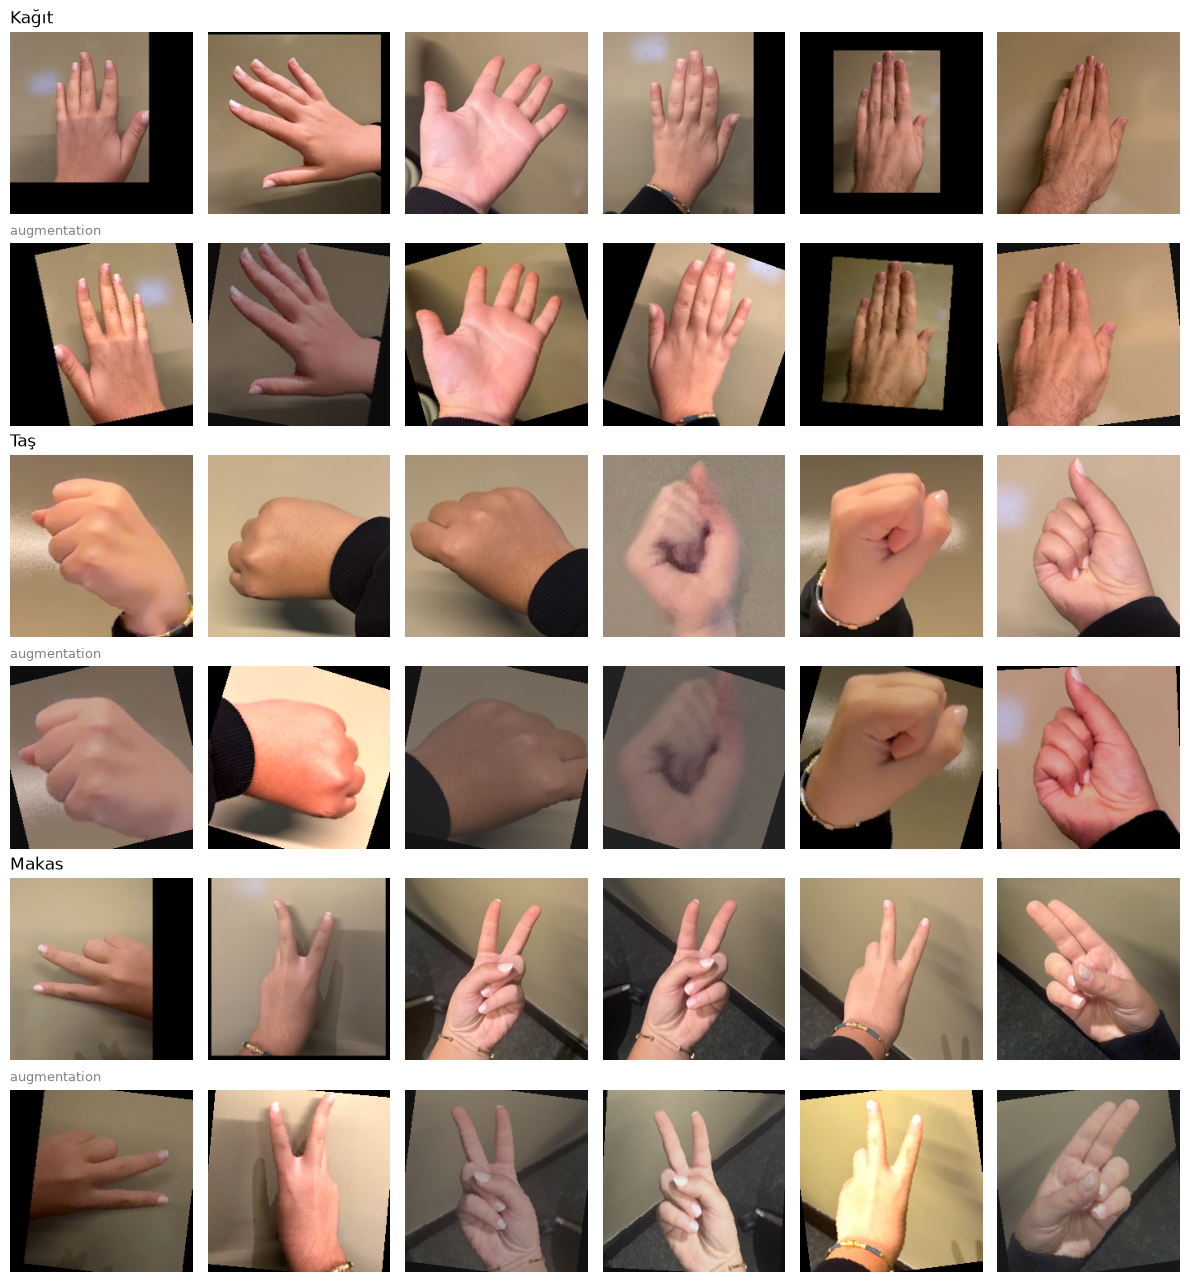

In [3]:
def to_rgb(t):  # normalize edilmiş tensör → (H, W, 3) 0..1 görüntü (panel ve çizimler için)
    return (t.permute(1, 2, 0) * torch.tensor(STD) + torch.tensor(MEAN)).clamp(0, 1)

raw_ds = datasets.ImageFolder(SPLIT / "train")
rng = random.Random(SEED)
fig, axes = plt.subplots(2 * len(CLASSES), 6, figsize=(12, 4.3 * len(CLASSES)))
for ci, c in enumerate(CLASSES):
    idx = rng.sample([i for i, t in enumerate(raw_ds.targets) if t == ci], 6)
    for j, i in enumerate(idx):
        img = raw_ds[i][0]
        axes[2 * ci, j].imshow(img); axes[2 * ci + 1, j].imshow(to_rgb(train_tf(img)))
        axes[2 * ci, j].set_title(TR[c] if j == 0 else "", loc="left", fontsize=12)
        axes[2 * ci + 1, j].set_title("augmentation" if j == 0 else "", loc="left", fontsize=9, color="gray")
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout(); plt.show()

### 0.4 Ortak eğitim, ölçüm ve dışa aktarma fonksiyonları
İki model de **aynı** fonksiyonlarla eğitilir ve ölçülür (adil karşılaştırma için):

- `train(...)`: her epoch'ta train datasıyla öğrenir, sonra validation'da **macro F1** ve loss ölçer. Validation macro F1'in en yüksek olduğu epoch'un ağırlıklarını saklar ve sonunda onlara döner. Her batch'ten sonra canlı paneli günceller.
- `evaluate(...)`: modeli bir datasette çalıştırır, macro F1, sınıf başına F1 ve karışıklık matrisini (confusion matrix) verir.
- `plot_history(...)`: train / validation F1 ve loss grafiği.
- `gradcam(...)`: modelin karar verirken fotoğrafın neresine baktığını gösteren ısı haritası.
- `export_onnx(...)`: modeli deneme sayfası ve web ürünü için ONNX formatına çevirir ve ONNX çıktısının PyTorch ile aynı olduğunu kontrol eder.

**Çıktıda bak:** bu hücre sadece fonksiyonları tanımlar, çıktı vermez.

In [4]:
def run_epoch(model, dl, opt=None, view=None, history=None):
    """opt verilirse eğitir, verilmezse sadece ölçer. (loss, macro F1, tahminler, gerçekler) döner."""
    train = opt is not None
    model.train(train)
    total, preds, ys = 0.0, [], []
    with torch.set_grad_enabled(train):
        for i, (x, y) in enumerate(dl, start=1):
            out = model(x)
            loss = F.cross_entropy(out, y, label_smoothing=0.1 if train else 0.0)
            if train:
                opt.zero_grad(); loss.backward(); opt.step()
                if view: view(model, history, i, len(dl), x=x, y=y)
            total += loss.item() * len(y)
            preds += out.argmax(1).tolist(); ys += y.tolist()
    return total / len(ys), f1_score(ys, preds, average="macro", zero_division=0), preds, ys


def train(model, epochs, lr, history, name, view=None, weight_decay=0.05):
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=weight_decay)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    best = max([h["val_f1"] for h in history], default=-1.0)
    best_state = {k: v.clone() for k, v in model.state_dict().items()}
    for _ in range(epochs):
        t0 = time.time()
        tr_loss, tr_f1, _, _ = run_epoch(model, train_dl, opt, view, history)
        va_loss, va_f1, _, _ = run_epoch(model, val_dl)
        sched.step()
        history.append(dict(train_loss=tr_loss, train_f1=tr_f1, val_loss=va_loss, val_f1=va_f1))
        if view: view(model, history, len(train_dl), len(train_dl), force=True)
        mark = ""
        if va_f1 > best:
            best, best_state, mark = va_f1, {k: v.clone() for k, v in model.state_dict().items()}, "  ← en iyi"
        print(f"[{name}] epoch {len(history):3d}  train F1 {tr_f1:.3f} loss {tr_loss:.3f} | "
              f"val F1 {va_f1:.3f} loss {va_loss:.3f} | {time.time() - t0:4.1f} sn{mark}")
    model.load_state_dict(best_state)
    print(f"[{name}] en iyi validation macro F1: {best:.3f} (bu ağırlıklar yüklendi)")
    return history


def plot_history(history, title, split_at=None):
    ep = range(1, len(history) + 1)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.8))
    for ax, key, label in [(a1, "f1", "Macro F1"), (a2, "loss", "Loss")]:
        ax.plot(ep, [h[f"train_{key}"] for h in history], label="train", color="#2563eb")
        ax.plot(ep, [h[f"val_{key}"] for h in history], label="validation", color="#ea580c")
        if split_at:
            ax.axvline(split_at + 0.5, color="gray", ls="--", lw=1)
        ax.set_title(f"{title} — {label}"); ax.set_xlabel("epoch"); ax.grid(alpha=0.3); ax.legend()
    a1.set_ylim(0, 1.02)
    plt.tight_layout(); plt.show()


def evaluate(model, dl, title):
    _, macro, preds, ys = run_epoch(model, dl)
    per_class = f1_score(ys, preds, average=None, labels=range(len(CLASSES)), zero_division=0)
    print(f"{title} — macro F1: {macro:.3f}\n")
    print(classification_report(ys, preds, target_names=[TR[c] for c in CLASSES], digits=3, zero_division=0))
    cm = confusion_matrix(ys, preds, labels=range(len(CLASSES)))
    fig, ax = plt.subplots(figsize=(4, 3.6))
    ax.imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, v, ha="center", va="center", color="white" if v > cm.max() / 2 else "black")
    names = [TR[c] for c in CLASSES]
    ax.set_xticks(range(len(names)), names); ax.set_yticks(range(len(names)), names)
    ax.set_xlabel("tahmin"); ax.set_ylabel("gerçek"); ax.set_title(title)
    plt.tight_layout(); plt.show()
    return dict(macro_f1=float(macro), per_class_f1={c: float(f) for c, f in zip(CLASSES, per_class)})


def gradcam(model, layer, x):
    """x: (1, 3, H, W). Seçilen katmanın aktivasyonlarını, tahmin edilen sınıfın gradyanıyla ağırlıklandırır."""
    acts, grads = {}, {}
    h1 = layer.register_forward_hook(lambda m, i, o: acts.__setitem__("a", o))
    h2 = layer.register_full_backward_hook(lambda m, gi, go: grads.__setitem__("g", go[0]))
    model.eval()
    x = x.clone().requires_grad_(True)
    out = model(x)
    cls = int(out.argmax(1))
    model.zero_grad(); out[0, cls].backward()
    h1.remove(); h2.remove()
    w = grads["g"].mean((2, 3), keepdim=True)
    cam = F.relu((w * acts["a"]).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam.detach().numpy(), cls, out.softmax(1)[0, cls].item()


def show_gradcam(model, layer, title, n_per_class=4):
    fig, axes = plt.subplots(len(CLASSES), n_per_class, figsize=(2.6 * n_per_class, 2.8 * len(CLASSES)))
    for ci in range(len(CLASSES)):
        idx = [i for i, t in enumerate(test_ds.targets) if t == ci][:: max(1, sum(np.array(test_ds.targets) == ci) // n_per_class)][:n_per_class]
        for j, i in enumerate(idx):
            x, y = test_ds[i]
            cam, pred, conf = gradcam(model, layer, x[None])
            ax = axes[ci, j]
            ax.imshow(to_rgb(x)); ax.imshow(cam, cmap="jet", alpha=0.45); ax.axis("off")
            ok = pred == y
            ax.set_title(f"{TR[CLASSES[y]]} → {TR[CLASSES[pred]]} %{conf * 100:.0f}", fontsize=9,
                         color="green" if ok else "red")
    fig.suptitle(f"{title} — Grad-CAM (kırmızı = karara en çok etki eden bölge)")
    plt.tight_layout(); plt.show()


def export_onnx(model, name, extra):
    """models/<name>.onnx + models/<name>.json (sınıflar, normalizasyon, metrikler)."""
    import onnxruntime as ort
    model.eval()
    path = MODELS / f"{name}.onnx"
    dummy = torch.randn(1, 3, IMG_SIZE, IMG_SIZE)
    torch.onnx.export(model, dummy, path, input_names=["input"], output_names=["logits"],
                      dynamic_axes={"input": {0: "batch"}, "logits": {0: "batch"}},
                      opset_version=17, dynamo=False)
    x = torch.stack([test_ds[i][0] for i in range(0, len(test_ds), max(1, len(test_ds) // 8))])
    with torch.no_grad():
        ref = model(x).numpy()
    got = ort.InferenceSession(str(path), providers=["CPUExecutionProvider"]).run(None, {"input": x.numpy()})[0]
    diff = float(np.abs(ref - got).max())
    assert diff < 1e-3, f"ONNX çıktısı PyTorch'tan farklı: {diff}"
    print(f"{path.name} ({path.stat().st_size / 1e6:.0f} MB) — ONNX ile PyTorch farkı {diff:.1e} ✓")

    # Web için küçük sürüm: tam bağlı katmanlar int8 (GitHub 100 MB sınırı + tarayıcıya hızlı iniş)
    from onnxruntime.quantization import QuantType, quantize_dynamic
    small = MODELS / f"{name}.int8.onnx"
    quantize_dynamic(path, small, op_types_to_quantize=["MatMul", "Gemm"], weight_type=QuantType.QInt8)
    sess = ort.InferenceSession(str(small), providers=["CPUExecutionProvider"])
    preds = [int(sess.run(None, {"input": x[None].numpy()})[0].argmax()) for x, _ in test_ds]
    int8_f1 = float(f1_score(test_ds.targets, preds, average="macro"))
    print(f"{small.name} ({small.stat().st_size / 1e6:.0f} MB) — test macro F1 {int8_f1:.3f} "
          f"(PyTorch: {extra['test']['macro_f1']:.3f})")

    meta = dict(name=name, classes=CLASSES, classes_tr=[TR[c] for c in CLASSES], input_size=IMG_SIZE,
                mean=MEAN, std=STD, crop_margin=1.4, int8_test_macro_f1=int8_f1, **extra)
    (MODELS / f"{name}.json").write_text(json.dumps(meta, ensure_ascii=False, indent=2))

---
## Bölüm 1 — Model A: Kendi CNN'in (sıfırdan)

### 1.1 Modeli kur
Onayladığın mimari: 5 blok (Conv 3×3 → BatchNorm → ReLU → MaxPool, kanallar 32-64-128-128-256), sonra iki tam bağlı katman. Ağırlıklar **rastgele** başlar; model sadece senin fotoğraflarından öğrenir.

**Çıktıda bak:** toplam yaklaşık 25.6M parametre.

In [5]:
def conv_block(c_in, c_out):
    return nn.Sequential(nn.Conv2d(c_in, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(), nn.MaxPool2d(2))

torch.manual_seed(SEED)
model_a = nn.Sequential(
    conv_block(3, 32), conv_block(32, 64), conv_block(64, 128), conv_block(128, 128), conv_block(128, 256),
    nn.Flatten(), nn.Dropout(0.5),
    nn.Linear(256 * 7 * 7, 2000), nn.ReLU(), nn.Dropout(0.5),
    nn.Linear(2000, len(CLASSES)),
)
n_conv = sum(p.numel() for m in model_a[:5] for p in m.parameters())
n_all = sum(p.numel() for p in model_a.parameters())
print(f"Model A: {n_all / 1e6:.1f}M parametre (conv blokları {n_conv / 1e6:.2f}M, tam bağlı {(n_all - n_conv) / 1e6:.1f}M)")

Model A: 25.6M parametre (conv blokları 0.54M, tam bağlı 25.1M)


### 1.2 Model A'yı eğit (canlı panel açılır)
60 epoch eğitim (lr 3e-4), **yaklaşık 6–8 dakika** sürer. Hücre başlayınca tarayıcıda **canlı eğitim paneli** açılır: modelin elinin fotoğrafında bulduklarını kulelerden bir şehir olarak görürsün; Conv, BatchNorm, ReLU ve MaxPool adımlarının şehre ne yaptığını izlersin. Açılmazsa çıktıdaki `Canlı panel: http://localhost:80xx/` linkine tıkla.

**Çıktıda bak:** her satır bir epoch. `val F1` zamanla yükselmeli. **Uyarı işareti:** `train F1` 1.0'a yakınken `val F1` çok düşük kalıyorsa model fotoğrafları ezberliyor (overfitting).

In [6]:
EPOCHS_A = 60
view_a = CNNLive(model_a, val_ds, to_rgb, CLASSES, epochs=EPOCHS_A)
hist_a = train(model_a, EPOCHS_A, 3e-4, [], "model_a", view=view_a)  # lr 3e-4: 1e-3 ilk epoch'larda dalgalanıyordu
view_a.close()
torch.save(model_a.state_dict(), MODELS / "model_a.pt")

Canlı panel: http://localhost:8002/  (tarayıcıda açılmadıysa bu linke tıkla)


[model_a] epoch   1  train F1 0.349 loss 3.347 | val F1 0.153 loss 1.192 |  4.1 sn  ← en iyi


[model_a] epoch   2  train F1 0.439 loss 1.324 | val F1 0.181 loss 1.152 |  4.0 sn  ← en iyi


[model_a] epoch   3  train F1 0.545 loss 1.078 | val F1 0.362 loss 0.987 |  3.8 sn  ← en iyi


[model_a] epoch   4  train F1 0.644 loss 0.891 | val F1 0.778 loss 0.753 |  3.9 sn  ← en iyi


...

[model_a] epoch  56  train F1 0.993 loss 0.341 | val F1 0.970 loss 0.095 |  4.1 sn


[model_a] epoch  57  train F1 0.990 loss 0.350 | val F1 0.970 loss 0.093 |  3.9 sn


[model_a] epoch  58  train F1 0.990 loss 0.340 | val F1 0.970 loss 0.093 |  4.0 sn


[model_a] epoch  59  train F1 0.993 loss 0.344 | val F1 0.970 loss 0.095 |  3.8 sn


[model_a] epoch  60  train F1 0.990 loss 0.354 | val F1 0.970 loss 0.096 |  3.8 sn
[model_a] en iyi validation macro F1: 1.000 (bu ağırlıklar yüklendi)


### 1.3 Eğitim grafiği
Soldaki grafik macro F1, sağdaki loss. Mavi train, turuncu validation.

**Çıktıda bak:** iki çizgi birlikte yükselmeli (F1) / düşmeli (loss). Train çizgisi yukarıda giderken validation yerinde sayıyor ya da loss'u yükseliyorsa → overfitting.

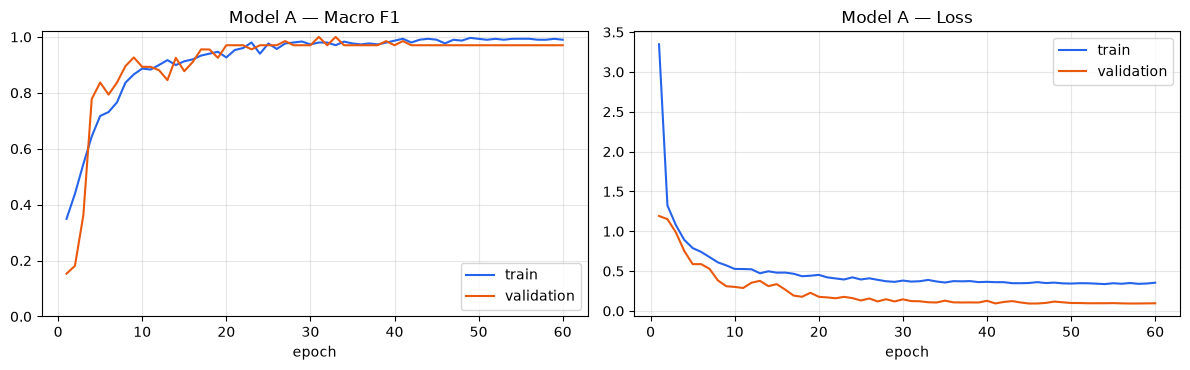

In [7]:
plot_history(hist_a, "Model A")

### 1.4 Test sonuçları (modelin hiç görmediği 70 fotoğraf)
**Macro F1** ana metriğimiz: üç hareketi eşit ağırlıkla değerlendirir. Altında sınıf başına precision / recall / F1 ve karışıklık matrisi var.

**Çıktıda bak:** macro F1. Matriste köşegen dışındaki sayılar hataları gösterir (örneğin satır *Makas*, sütun *Kağıt* = makası kağıt sanmış).

Model A — test — macro F1: 0.987

              precision    recall  f1-score   support

       Kağıt      0.962     1.000     0.980        25
         Taş      1.000     0.960     0.980        25
       Makas      1.000     1.000     1.000        20

    accuracy                          0.986        70
   macro avg      0.987     0.987     0.987        70
weighted avg      0.986     0.986     0.986        70



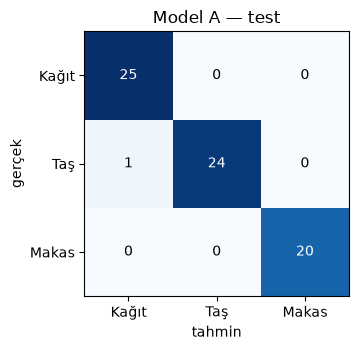

In [8]:
res_a = evaluate(model_a, test_dl, "Model A — test")

### 1.5 Grad-CAM — Model A nereye bakıyor?
Birkaç test fotoğrafının üstüne ısı haritası: kırmızı bölgeler modelin kararını en çok etkileyen yerler. Başlıkta `gerçek → tahmin %güven` yazar (yeşil doğru, kırmızı yanlış).

**Çıktıda bak:** iyi bir model **parmaklara ve elin şekline** bakar. Arka plana, kola ya da siyah kenarlara bakıyorsa yanlış şeyi öğrenmiş olabilir. (Sadece inceleme içindir; kazananı F1 ve canlı testle seçeceğiz.)

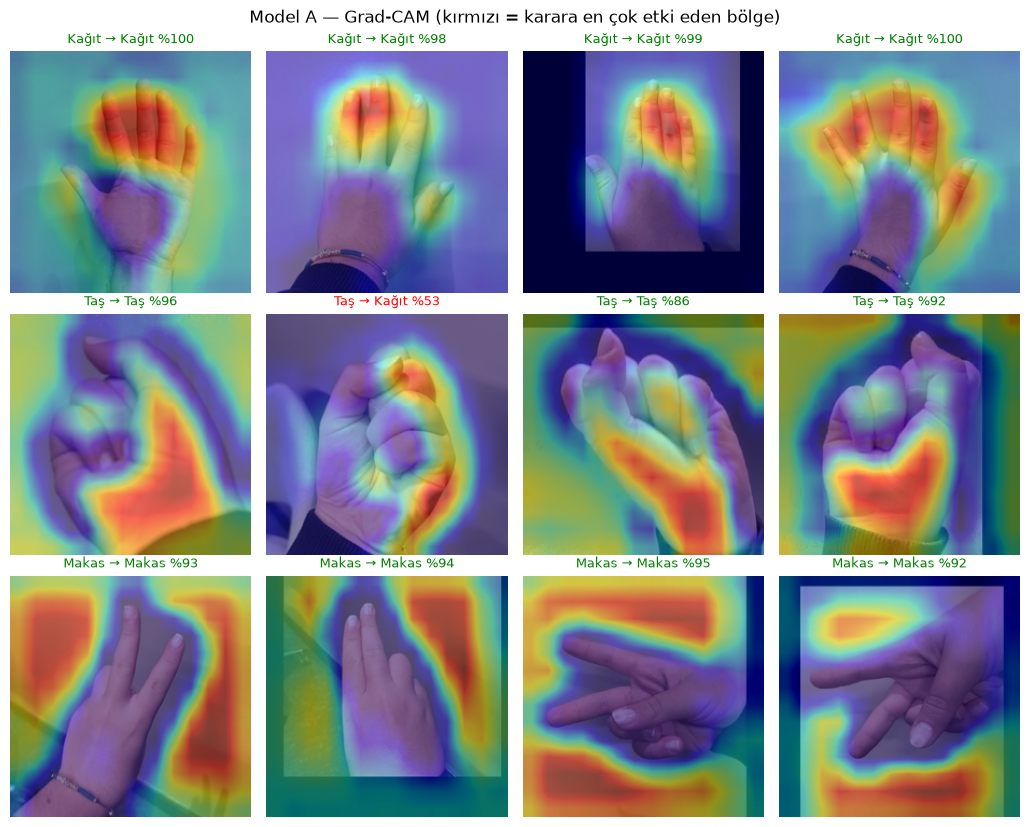

In [9]:
show_gradcam(model_a, model_a[4][2], "Model A")  # 5. bloğun ReLU çıkışı (14×14)

### 1.6 ONNX olarak dışa aktar
Modeli `models/model_a.onnx` olarak kaydeder: deneme sayfası ve web ürünü bu dosyayı kullanacak. Yanına sınıflar, normalizasyon ve test metriklerini içeren `models/model_a.json` yazılır.

İki dosya çıkar:
- `model_a.onnx` (~100 MB, tam hassasiyet): deneme sayfasında sunucuda kullanılır. GitHub'ın 100 MB sınırını aştığı için repoya girmez.
- `model_a.int8.onnx` (~27 MB): tam bağlı katmanları 8-bit'e sıkıştırılmış sürüm. Repoya ve web ürününe bu girer.

**Çıktıda bak:** `✓` (ONNX modeli PyTorch modeliyle aynı sonucu veriyor) ve int8 sürümün test macro F1'i PyTorch'takine çok yakın olmalı.

In [10]:
export_onnx(model_a, "model_a", dict(title="Model A — Sıfırdan CNN", params=n_all, test=res_a,
                                     best_val_f1=max(h["val_f1"] for h in hist_a), history=hist_a))

/tmp/ipykernel_442603/1223809799.py:111: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(model, dummy, path, input_names=["input"], output_names=["logits"],


model_a.onnx (103 MB) — ONNX ile PyTorch farkı 1.1e-06 ✓


model_a.int8.onnx (27 MB) — test macro F1 0.987 (PyTorch: 0.987)


---
## Bölüm 2 — Model B: ConvNeXt-Tiny (pretrained, fine-tuning)

> ⏸ **Bu bölümü Model A'yı kamerada denedikten sonra çalıştır.** (Bölüm 0'ı yeniden çalıştırman gerekebilir.)

### 2.1 Pretrained modeli yükle
ImageNet'te milyonlarca görselle önceden eğitilmiş ConvNeXt-Tiny'yi indirir, son katmanını 3 sınıfa (Taş, Kağıt, Makas) göre değiştirir.

**Çıktıda bak:** yaklaşık 27.8M parametre.

In [5]:
import timm

torch.manual_seed(SEED)
model_b = timm.create_model("convnext_tiny.fb_in22k_ft_in1k", pretrained=True, num_classes=len(CLASSES))

def set_trainable(model, parts):
    """Sadece verilen parçalar öğrenir, geri kalan her şey donar (requires_grad=False)."""
    for p in model.parameters():
        p.requires_grad = False
    for part in parts:
        for p in part.parameters():
            p.requires_grad = True
    n = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"öğrenen parametre: {n:,} / {sum(p.numel() for p in model.parameters()):,}")

print(f"Model B: {sum(p.numel() for p in model_b.parameters()) / 1e6:.1f}M parametre")

/home/coder/workspaces/rock-paper-scissors-computer-vision-2nd-week/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Model B: 27.8M parametre


### 2.2 Model B'yi fine-tune et (canlı panel açılır)
CPU'da hızlı olsun diye iki adım:
1. **Gövde donuk**, sadece karar katmanı (`head`) öğrenir: 5 epoch, lr 1e-3.
2. **Son aşama çözülür** (`stages[3]` + `head`): 10 epoch, daha küçük lr (1e-4), hazır bilgiyi bozmamak için.

Toplam **yaklaşık 5–8 dakika**. Panelde donuk kısımlar **gri**, öğrenen kısımlar **mavi**: 2. adımda son aşama maviye döner.

**Çıktıda bak:** pretrained model sayesinde `val F1` daha ilk epoch'larda yüksek olmalı.

In [6]:
EPOCHS_B1, EPOCHS_B2 = 5, 10
view_b = FineTuneLive(model_b, val_ds, to_rgb, CLASSES, epochs=EPOCHS_B1 + EPOCHS_B2)
set_trainable(model_b, [model_b.head])                               # 1) gövde donuk
hist_b = train(model_b, EPOCHS_B1, 1e-3, [], "model_b", view=view_b)
set_trainable(model_b, [model_b.stages[-1], model_b.head])           # 2) son aşama çözülür
hist_b = train(model_b, EPOCHS_B2, 1e-4, hist_b, "model_b", view=view_b)
view_b.close()
torch.save(model_b.state_dict(), MODELS / "model_b.pt")

Canlı panel: http://localhost:8002/  (tarayıcıda açılmadıysa bu linke tıkla)


öğrenen parametre: 3,843 / 27,822,435

[model_b] epoch   1  train F1 0.654 loss 0.876 | val F1 0.875 loss 0.483 |  4.0 sn  ← en iyi


[model_b] epoch   2  train F1 0.931 loss 0.488 | val F1 0.850 loss 0.331 |  3.7 sn


[model_b] epoch   3  train F1 0.951 loss 0.415 | val F1 0.879 loss 0.296 |  3.8 sn  ← en iyi


...

[model_b] epoch  11  train F1 1.000 loss 0.307 | val F1 0.984 loss 0.139 |  6.2 sn


[model_b] epoch  12  train F1 1.000 loss 0.309 | val F1 1.000 loss 0.126 |  5.2 sn


[model_b] epoch  13  train F1 1.000 loss 0.306 | val F1 1.000 loss 0.130 |  5.8 sn


[model_b] epoch  14  train F1 1.000 loss 0.306 | val F1 1.000 loss 0.131 | 12.2 sn


[model_b] epoch  15  train F1 1.000 loss 0.304 | val F1 1.000 loss 0.131 |  5.1 sn
[model_b] en iyi validation macro F1: 1.000 (bu ağırlıklar yüklendi)


### 2.3 Eğitim grafiği
Kesikli çizgi, 1. adımdan (gövde donuk) 2. adıma (son aşama çözüldü) geçişi gösterir.

**Çıktıda bak:** Model A'nın grafiğiyle karşılaştır. Ne kadar hızlı yükseliyor?

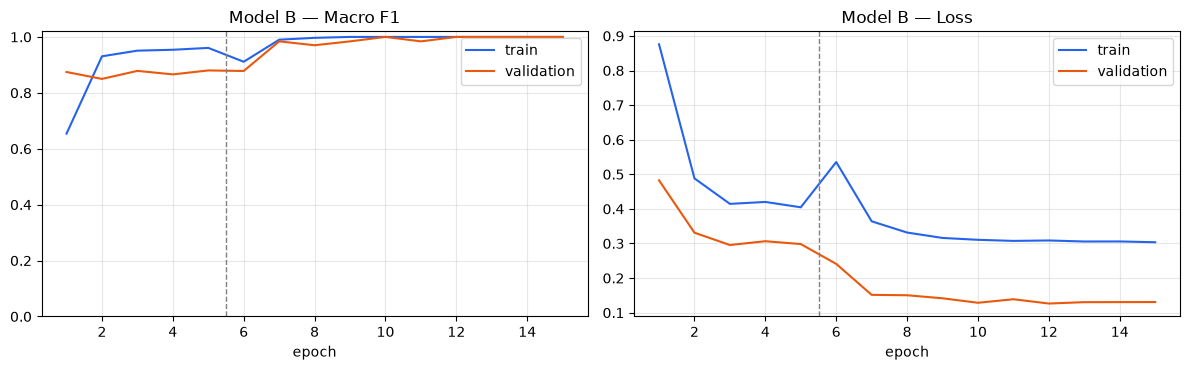

In [7]:
plot_history(hist_b, "Model B", split_at=EPOCHS_B1)

### 2.4 Test sonuçları
Model A ile aynı 70 test fotoğrafı.

**Çıktıda bak:** macro F1 ve hangi hareketlerin karıştırıldığı.

Model B — test — macro F1: 1.000

              precision    recall  f1-score   support

       Kağıt      1.000     1.000     1.000        25
         Taş      1.000     1.000     1.000        25
       Makas      1.000     1.000     1.000        20

    accuracy                          1.000        70
   macro avg      1.000     1.000     1.000        70
weighted avg      1.000     1.000     1.000        70



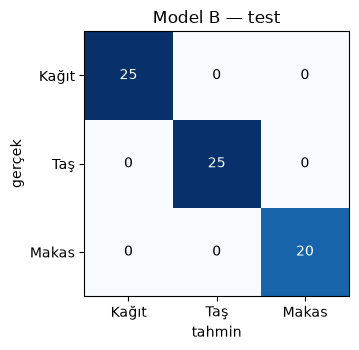

In [8]:
res_b = evaluate(model_b, test_dl, "Model B — test")

### 2.5 Grad-CAM — Model B nereye bakıyor?
**Çıktıda bak:** Model A'nın ısı haritalarıyla karşılaştır. Hangisi parmaklara daha çok bakıyor?

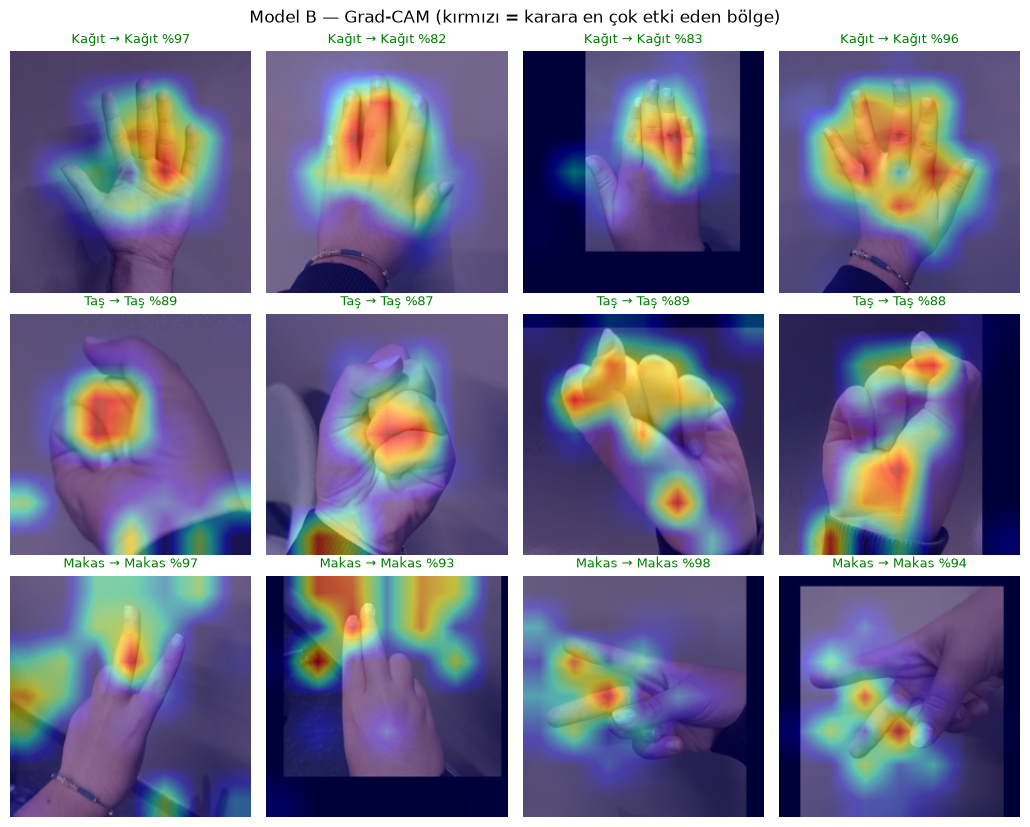

In [9]:
show_gradcam(model_b, model_b.stages[-1], "Model B")  # son aşamanın çıkışı (7×7)

### 2.6 ONNX olarak dışa aktar
**Çıktıda bak:** `✓` ve int8 sürümün (`model_b.int8.onnx`, ~30 MB) test macro F1'i PyTorch'takine yakın olmalı.

In [10]:
export_onnx(model_b, "model_b", dict(title="Model B — ConvNeXt-Tiny (pretrained)",
                                     params=sum(p.numel() for p in model_b.parameters()), test=res_b,
                                     best_val_f1=max(h["val_f1"] for h in hist_b), history=hist_b))

/tmp/ipykernel_501504/1223809799.py:111: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(model, dummy, path, input_names=["input"], output_names=["logits"],


model_b.onnx (111 MB) — ONNX ile PyTorch farkı 9.5e-06 ✓


model_b.int8.onnx (34 MB) — test macro F1 0.985 (PyTorch: 1.000)


---
## Bölüm 3 — İki modelin karşılaştırması

> İki model de eğitildikten sonra çalıştır. Kaydedilen `models/model_a.json` ve `models/model_b.json` dosyalarından okur, yani eğitimi tekrar çalıştırmak gerekmez.

### 3.1 Karşılaştırma tablosu
**Çıktıda bak:** test macro F1 ana metrik. Sınıf başına F1, hangi modelin hangi harekette zorlandığını gösterir.

In [5]:
import pandas as pd

rows = {}
for name in ["model_a", "model_b"]:
    p = MODELS / f"{name}.json"
    if not p.exists():
        print(f"{name} henüz eğitilmedi"); continue
    m = json.loads(p.read_text())
    rows[m["title"]] = {"Parametre": f"{m['params'] / 1e6:.1f}M", "Epoch": len(m["history"]),
                        "En iyi val macro F1": round(m["best_val_f1"], 3),
                        "Test macro F1": round(m["test"]["macro_f1"], 3),
                        **{f"F1 {TR[c]}": round(m["test"]["per_class_f1"][c], 3) for c in CLASSES}}
pd.DataFrame(rows).T

,Parametre,Epoch,En iyi val macro F1,Test macro F1,F1 Kağıt,F1 Taş,F1 Makas
Model A — Sıfırdan CNN,25.6M,60,1.0,0.987,0.98,0.98,1.0
Model B — ConvNeXt-Tiny (pretrained),27.8M,15,1.0,1.0,1.0,1.0,1.0


### 3.2 Eğitim eğrileri yan yana
**Çıktıda bak:** pretrained model (B) ne kadar daha hızlı öğreniyor? Hangisinde train ile validation arası fark (overfitting) daha büyük?

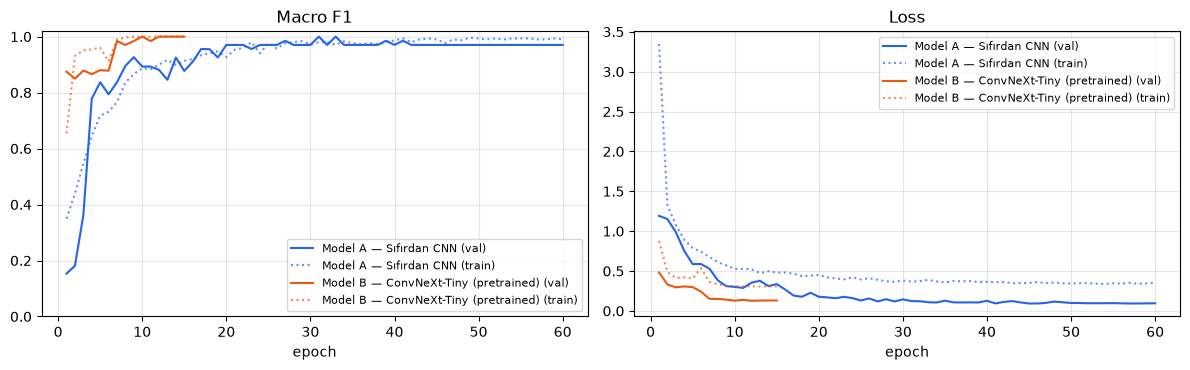

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for name, color in [("model_a", "#2563eb"), ("model_b", "#ea580c")]:
    p = MODELS / f"{name}.json"
    if not p.exists():
        continue
    m = json.loads(p.read_text()); h = m["history"]; ep = range(1, len(h) + 1)
    for ax, key in zip(axes, ["f1", "loss"]):
        ax.plot(ep, [x[f"val_{key}"] for x in h], color=color, label=f"{m['title']} (val)")
        ax.plot(ep, [x[f"train_{key}"] for x in h], color=color, ls=":", alpha=0.7, label=f"{m['title']} (train)")
for ax, t in zip(axes, ["Macro F1", "Loss"]):
    ax.set_title(t); ax.set_xlabel("epoch"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
axes[0].set_ylim(0, 1.02)
plt.tight_layout(); plt.show()

### 3.3 Grad-CAM yan yana
Aynı test fotoğrafları, solda Model A, sağda Model B. (Bu hücre için iki modelin de bu oturumda yüklü olması gerekir: `models/*.pt` dosyalarından yüklenir.)

**Çıktıda bak:** iki model aynı yere mi bakıyor? Hangisi elin şekline daha çok odaklanıyor?

/home/coder/workspaces/rock-paper-scissors-computer-vision-2nd-week/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


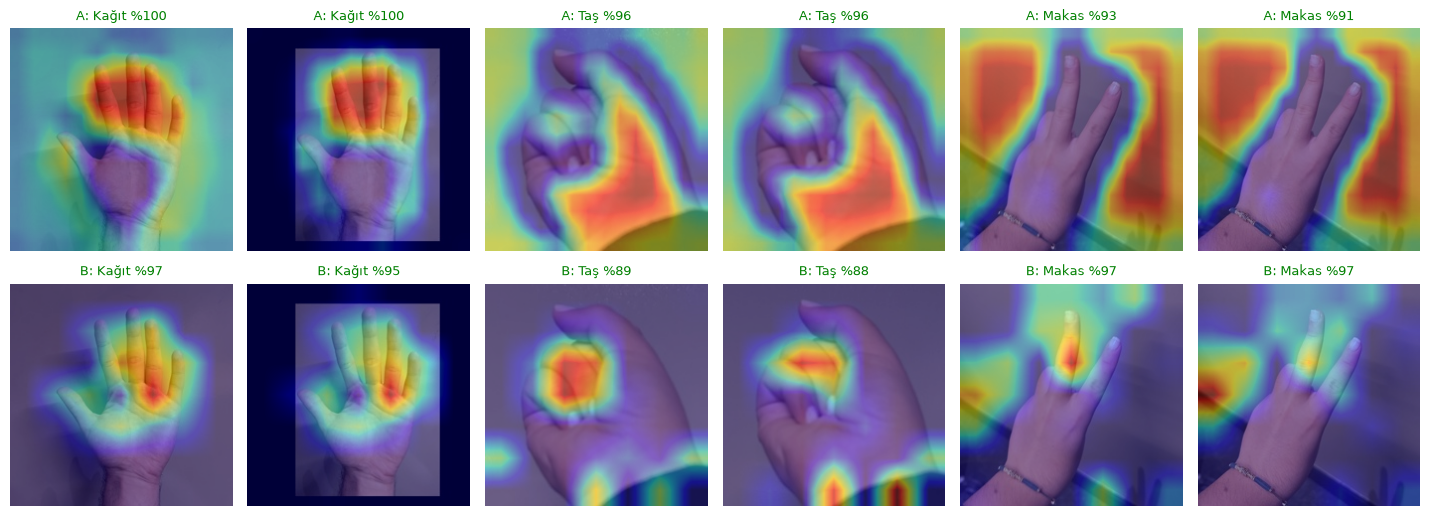

In [7]:
if "model_a" not in dir():
    def conv_block(c_in, c_out):  # Bölüm 1.1'deki ile aynı
        return nn.Sequential(nn.Conv2d(c_in, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(), nn.MaxPool2d(2))
    model_a = nn.Sequential(conv_block(3, 32), conv_block(32, 64), conv_block(64, 128), conv_block(128, 128),
                            conv_block(128, 256), nn.Flatten(), nn.Dropout(0.5), nn.Linear(256 * 7 * 7, 2000),
                            nn.ReLU(), nn.Dropout(0.5), nn.Linear(2000, len(CLASSES)))
    model_a.load_state_dict(torch.load(MODELS / "model_a.pt"))
if "model_b" not in dir():
    import timm
    model_b = timm.create_model("convnext_tiny.fb_in22k_ft_in1k", pretrained=False, num_classes=len(CLASSES))
    model_b.load_state_dict(torch.load(MODELS / "model_b.pt"))

idx = [i for ci in range(len(CLASSES)) for i in [j for j, t in enumerate(test_ds.targets) if t == ci][:2]]
fig, axes = plt.subplots(2, len(idx), figsize=(2.4 * len(idx), 5.4))
for col, i in enumerate(idx):
    x, y = test_ds[i]
    for row, (model, layer, name) in enumerate([(model_a, model_a[4][2], "A"), (model_b, model_b.stages[-1], "B")]):
        cam, pred, conf = gradcam(model, layer, x[None])
        ax = axes[row, col]
        ax.imshow(to_rgb(x)); ax.imshow(cam, cmap="jet", alpha=0.45); ax.axis("off")
        ax.set_title(f"{name}: {TR[CLASSES[pred]]} %{conf * 100:.0f}", fontsize=9,
                     color="green" if pred == y else "red")
plt.tight_layout(); plt.show()